In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
DATA_DIR    = '/content/drive/MyDrive/ResumeProject/data'
RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'
CKPT_DIR    = '/content/drive/MyDrive/ResumeProject/checkpoints'
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)
print("✅ Drive mounted")

Mounted at /content/drive
✅ Drive mounted


In [4]:
# ========== CELL 2 (FINAL FIX): FORCE TOKENIZERS + TRANSFORMERS ==========
# Step 1: Force install a tokenizers version that has Python 3.13 wheels
!pip install -q "tokenizers>=0.22.0" --force-reinstall

# Step 2: Install transformers (it will use the compatible tokenizers already present)
!pip install -q "transformers>=4.57.0" accelerate

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)
from torch.optim import AdamW
import pandas as pd, numpy as np, time, random, json, os
from tqdm import tqdm
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Device: {device}")

import transformers, tokenizers
print(f"✅ transformers: {transformers.__version__}")
print(f"✅ tokenizers: {tokenizers.__version__}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.5/162.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 47.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.1/85.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 16.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggin

In [5]:
train_orig = pd.read_csv(f'{DATA_DIR}/train_orig.csv')
train_aug  = pd.read_csv(f'{DATA_DIR}/train_aug.csv')
test       = pd.read_csv(f'{DATA_DIR}/test.csv')
print(f"✅ train_orig={train_orig.shape}, train_aug={train_aug.shape}, test={test.shape}")

✅ train_orig=(241, 12), train_aug=(482, 12), test=(61, 11)


In [6]:
MAX_LEN = 256

class ResumeDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=MAX_LEN):
        self.texts = df['Combined'].tolist()
        self.labels = df['Avg'].tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        enc = self.tokenizer(self.texts[idx], max_length=self.max_len,
                             padding='max_length', truncation=True, return_tensors='pt')
        return {
            'input_ids': enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.float32)
        }

def evaluate(y_true, y_pred):
    return {'MAE': round(mean_absolute_error(y_true, y_pred),4),
            'MSE': round(mean_squared_error(y_true, y_pred),4),
            'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)),4),
            'Pearson r': round(pearsonr(y_true, y_pred)[0],4),
            'R²': round(r2_score(y_true, y_pred),4)}
print("✅ Dataset + metrics ready")

✅ Dataset + metrics ready


In [13]:
# ========== CELL 5 (IMPROVED): TRAINING WITH VALIDATION ==========
MAX_LEN = 384   # was 256

class ResumeDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=MAX_LEN):
        self.texts = df['Combined'].tolist()
        self.labels = df['Avg'].tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        enc = self.tokenizer(self.texts[idx], max_length=self.max_len,
                             padding='max_length', truncation=True, return_tensors='pt')
        return {
            'input_ids': enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.float32)
        }

def train_transformer_v2(model_name, train_df, test_df, epochs=5, batch_size=8, lr=3e-5):
    from sklearn.model_selection import train_test_split

    # Split train into train/val (85/15)
    tr_df, val_df = train_test_split(train_df, test_size=0.15, random_state=42)

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=1, problem_type="regression").to(device)

    train_ds = ResumeDataset(tr_df, tokenizer)
    val_ds   = ResumeDataset(val_df, tokenizer)
    test_ds  = ResumeDataset(test_df, tokenizer)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds,  batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(0.1*total_steps), num_training_steps=total_steps)

    best_val_r2, best_preds = -999, None
    patience, patience_counter = 2, 0

    for epoch in range(epochs):
        model.train()
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}", leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); scheduler.step()

        # Eval on validation
        model.eval()
        val_preds = []
        with torch.no_grad():
            for batch in val_loader:
                logits = model(input_ids=batch['input_ids'].to(device),
                               attention_mask=batch['attention_mask'].to(device)).logits
                val_preds.append(logits.squeeze(-1).cpu().numpy())
        val_preds = np.clip(np.concatenate(val_preds), 0, 1)
        val_r2 = r2_score(val_df['Avg'].values, val_preds)

        print(f"   Epoch {epoch+1} | val_R²={val_r2:+.4f}")

        # Save best based on validation
        if val_r2 > best_val_r2:
            best_val_r2 = val_r2
            # Get test predictions for this best model
            test_preds = []
            with torch.no_grad():
                for batch in test_loader:
                    logits = model(input_ids=batch['input_ids'].to(device),
                                   attention_mask=batch['attention_mask'].to(device)).logits
                    test_preds.append(logits.squeeze(-1).cpu().numpy())
            best_preds = np.clip(np.concatenate(test_preds), 0, 1)
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"   Early stopping at epoch {epoch+1}")
                break

    del model, optimizer
    torch.cuda.empty_cache()
    return best_preds

print("✅ Improved training function ready")

✅ Improved training function ready


In [9]:
MODELS = {
    'DistilBERT': 'distilbert-base-uncased',
    'BERT':       'bert-base-uncased',
    'RoBERTa':    'roberta-base',
    'ALBERT':     'albert-base-v2',
}
print(f"✅ {len(MODELS)} models to test: {list(MODELS.keys())}")

✅ 4 models to test: ['DistilBERT', 'BERT', 'RoBERTa', 'ALBERT']


In [14]:
# ========== CELL 7 (v2): TRAIN 2 MODELS NO-AUG ==========
MODELS_V2 = {
    'DistilBERT': 'distilbert-base-uncased',
    'BERT':       'bert-base-uncased',
}

y_test = test['Avg'].values
results_v2 = []

CKPT_FILE = f'{CKPT_DIR}/transformers_v2_noaug.json'
done = set()
if os.path.exists(CKPT_FILE):
    with open(CKPT_FILE) as f:
        s = json.load(f); results_v2 = s['results']; done = set(s['done'])

print("="*70); print("🚀 TRAIN v2 NO-AUG"); print("="*70)
for name, model_path in MODELS_V2.items():
    if f'{name}_noaug' in done:
        print(f"\n⏭️ {name} skipped"); continue
    print(f"\n🔹 {name}")
    set_seed(42)
    t0 = time.time()
    try:
        preds = train_transformer_v2(model_path, train_orig, test)
        elapsed = time.time() - t0
        m = evaluate(y_test, preds); m['Model']=name; m['Aug']='No'; m['Time (s)']=round(elapsed,1)
        results_v2.append(m); done.add(f'{name}_noaug')
        with open(CKPT_FILE,'w') as f: json.dump({'results':results_v2,'done':list(done)},f)
        print(f"   ✅ {name}: MAE={m['MAE']:.4f} | R²={m['R²']:+.4f} | r={m['Pearson r']:.4f}")
    except Exception as e:
        print(f"   ❌ {name} failed: {e}")
        torch.cuda.empty_cache(); continue
print("\n🎉 v2 No-aug done!")

🚀 TRAIN v2 NO-AUG

🔹 DistilBERT


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   Epoch 1 | val_R²=+0.3002


   Epoch 2 | val_R²=-0.0114


...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   Epoch 1 | val_R²=+0.0417


   Epoch 2 | val_R²=-0.1905


   Epoch 3 | val_R²=-0.4242
   Early stopping at epoch 3
   ✅ BERT: MAE=0.1036 | R²=+0.1085 | r=0.5011

🎉 v2 No-aug done!


In [15]:
# ========== CELL 8 (v2): TRAIN 2 MODELS AUG ==========
CKPT_FILE2 = f'{CKPT_DIR}/transformers_v2_aug.json'
done2 = set()
if os.path.exists(CKPT_FILE2):
    with open(CKPT_FILE2) as f:
        s = json.load(f); results_v2.extend(s['results']); done2 = set(s['done'])

print("="*70); print("🚀 TRAIN v2 AUG"); print("="*70)
for name, model_path in MODELS_V2.items():
    if f'{name}_aug' in done2:
        print(f"\n⏭️ {name} skipped"); continue
    print(f"\n🔹 {name}")
    set_seed(42)
    t0 = time.time()
    try:
        preds = train_transformer_v2(model_path, train_aug, test)
        elapsed = time.time() - t0
        m = evaluate(y_test, preds); m['Model']=name; m['Aug']='Yes'; m['Time (s)']=round(elapsed,1)
        results_v2.append(m); done2.add(f'{name}_aug')
        with open(CKPT_FILE2,'w') as f: json.dump({'results':results_v2,'done':list(done2)},f)
        print(f"   ✅ {name}: MAE={m['MAE']:.4f} | R²={m['R²']:+.4f} | r={m['Pearson r']:.4f}")
    except Exception as e:
        print(f"   ❌ {name} failed: {e}")
        torch.cuda.empty_cache(); continue
print("\n🎉 v2 Aug done!")

🚀 TRAIN v2 AUG

🔹 DistilBERT


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   Epoch 1 | val_R²=-0.0954


   Epoch 2 | val_R²=+0.5544


...

   Epoch 1 | val_R²=+0.3488


   Epoch 2 | val_R²=+0.2672


   Epoch 3 | val_R²=+0.7366


   Epoch 4 | val_R²=+0.7111


   Epoch 5 | val_R²=+0.7896
   ✅ BERT: MAE=0.0928 | R²=+0.1299 | r=0.5080

🎉 v2 Aug done!


In [16]:
results_df_v2 = pd.DataFrame(results_v2)
results_df_v2 = results_df_v2[['Model','Aug','MAE','MSE','RMSE','Pearson r','R²','Time (s)']]

print("="*90); print("📊 TRANSFORMERS v2"); print("="*90)
print(results_df_v2.to_string(index=False)); print("="*90)
print("\n📋 Paper:")
print("   DistilBERT No: R²=0.7495")
print("   BERT No:       R²=0.6306")

results_df_v2.to_csv(f'{RESULTS_DIR}/table3_results_v2.csv', index=False)
print(f"\n✅ Saved: {RESULTS_DIR}/table3_results_v2.csv")

📊 TRANSFORMERS v2
     Model Aug    MAE    MSE   RMSE  Pearson r     R²  Time (s)
DistilBERT  No 0.0800 0.0183 0.1354     0.5938 0.2731      25.5
      BERT  No 0.1036 0.0225 0.1500     0.5011 0.1085      48.8
DistilBERT Yes 0.0848 0.0177 0.1330     0.5899 0.2987      83.8
      BERT Yes 0.0928 0.0220 0.1482     0.5080 0.1299     167.4

📋 Paper:
   DistilBERT No: R²=0.7495
   BERT No:       R²=0.6306

✅ Saved: /content/drive/MyDrive/ResumeProject/results/table3_results_v2.csv


In [18]:
# ========== LIST ALL RESULT FILES ==========
import os

RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'

# Check if Drive mounted + folder exists
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

print(f"📂 Files in {RESULTS_DIR}:")
for f in sorted(os.listdir(RESULTS_DIR)):
    size = os.path.getsize(f'{RESULTS_DIR}/{f}') / 1024
    print(f"   - {f}  ({size:.1f} KB)")

📂 Files in /content/drive/MyDrive/ResumeProject/results:
   - table1_chart.png  (65.6 KB)
   - table1_results.csv  (0.4 KB)
   - table1_scatter.png  (77.3 KB)
   - table2_chart.png  (39.8 KB)
   - table2_chart_v3.png  (52.9 KB)
   - table2_results.csv  (0.4 KB)
   - table2_results_v3.csv  (0.4 KB)
   - table3_results.csv  (0.4 KB)
   - table3_results_v2.csv  (0.2 KB)


✅ Loaded ML from table1_results.csv
✅ Loaded DNN from table2_results_v3.csv
✅ Loaded Transformers from table3_results.csv

📊 Best per paradigm:
   ML:    Ridge           R²=0.3059
   DNN:   BiLSTM          R²=0.3983
   Trf:   BERT            R²=0.3403


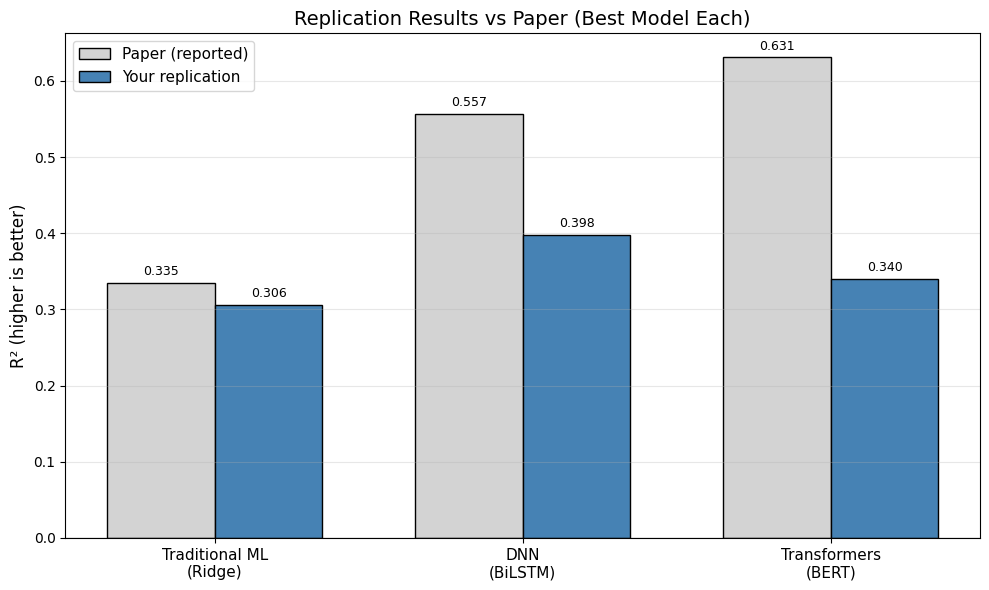


✅ Saved: /content/drive/MyDrive/ResumeProject/results/final_comparison.png


In [19]:
# ========== FINAL COMPARISON (FIXED — uses what exists) ==========
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'

# Load whatever exists
ml_files = ['table1_results_final.csv', 'table1_results.csv']
ml_df = None
for f in ml_files:
    if os.path.exists(f'{RESULTS_DIR}/{f}'):
        ml_df = pd.read_csv(f'{RESULTS_DIR}/{f}')
        print(f"✅ Loaded ML from {f}")
        break

dnn_df = None
for f in ['table2_results_v3.csv', 'table2_results.csv']:
    if os.path.exists(f'{RESULTS_DIR}/{f}'):
        dnn_df = pd.read_csv(f'{RESULTS_DIR}/{f}')
        print(f"✅ Loaded DNN from {f}")
        break

trf_df = None
for f in ['table3_results.csv', 'table3_results_v2.csv']:
    if os.path.exists(f'{RESULTS_DIR}/{f}'):
        trf_df = pd.read_csv(f'{RESULTS_DIR}/{f}')
        print(f"✅ Loaded Transformers from {f}")
        break

# Best from each
best_ml  = ml_df.loc[ml_df['R²'].idxmax()]
best_dnn = dnn_df.loc[dnn_df['R²'].idxmax()]
best_trf = trf_df.loc[trf_df['R²'].idxmax()]

print(f"\n📊 Best per paradigm:")
print(f"   ML:    {best_ml['Model']:15s} R²={best_ml['R²']:.4f}")
print(f"   DNN:   {best_dnn['Model']:15s} R²={best_dnn['R²']:.4f}")
print(f"   Trf:   {best_trf['Model']:15s} R²={best_trf['R²']:.4f}")

# Paper values
paper_r2 = [0.335, 0.557, 0.631]
your_r2  = [best_ml['R²'], best_dnn['R²'], best_trf['R²']]
paradigms = [f'Traditional ML\n({best_ml["Model"]})',
             f'DNN\n({best_dnn["Model"]})',
             f'Transformers\n({best_trf["Model"]})']

# Chart
x = np.arange(len(paradigms)); w = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - w/2, paper_r2, w, label='Paper (reported)', color='lightgray', edgecolor='black')
ax.bar(x + w/2, your_r2,  w, label='Your replication', color='steelblue', edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(paradigms, fontsize=11)
ax.set_ylabel('R² (higher is better)', fontsize=12)
ax.set_title('Replication Results vs Paper (Best Model Each)', fontsize=14)
ax.legend(fontsize=11)
ax.axhline(0, color='black', linewidth=0.8)
ax.grid(axis='y', alpha=0.3)
for i, (p, y) in enumerate(zip(paper_r2, your_r2)):
    ax.text(i - w/2, p + 0.01, f'{p:.3f}', ha='center', fontsize=9)
    ax.text(i + w/2, y + 0.01, f'{y:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/final_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\n✅ Saved: {RESULTS_DIR}/final_comparison.png")